In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Set plot styling
sns.set_theme(style="whitegrid")

# Load dataset directly from source
url = "https://raw.githubusercontent.com/alexeygrigorev/datasets/master/housing.csv"
df = pd.read_csv(url)

# Check the head of the data
print("Dataset Head:")
display(df.head())

# Check info, data types, and null counts
print("\nDataset Info Summary:")
df.info()

Dataset Head:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY



Dataset Info Summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [17]:
# Create domain-specific ratios to capture structural and living density patterns
df['rooms_per_household'] = df['total_rooms'] / df['households']
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms']
df['population_per_household'] = df['population'] / df['households']

# Select features and target variable
features = [
    'housing_median_age', 'total_rooms', 'total_bedrooms',
    'median_income', 'rooms_per_household', 'bedrooms_per_room',
    'population_per_household', 'ocean_proximity'
]
target = 'median_house_value'

X = df[features]
y = df[target]

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

Features shape: (20640, 8)
Target shape: (20640,)


In [18]:
def remove_outliers(X_data, y_data, column):
    Q1 = X_data[column].quantile(0.25)
    Q3 = X_data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    mask = (X_data[column] >= lower_bound) & (X_data[column] <= upper_bound)
    return X_data[mask], y_data[mask]

# Clean extreme values from median income and rooms per household
X, y = remove_outliers(X, y, 'median_income')
X, y = remove_outliers(X, y, 'rooms_per_household')

print(f"Shape after cleaning outliers: {X.shape}")

Shape after cleaning outliers: (19520, 8)


In [19]:
# First split: Separate 20% for Final Test, leaving 80% for Train + Validation
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Second split: Split the 80% into 60% Training and 20% Validation
# (test_size=0.25 of 80% equals 20% of the overall total)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=42)

print(f"Training Set:   {X_train.shape[0]} rows ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Validation Set: {X_val.shape[0]} rows ({X_val.shape[0]/len(X)*100:.1f}%)")
print(f"Test Set:       {X_test.shape[0]} rows ({X_test.shape[0]/len(X)*100:.1f}%)")

Training Set:   11712 rows (60.0%)
Validation Set: 3904 rows (20.0%)
Test Set:       3904 rows (20.0%)


In [20]:
# Numerical pipeline: impute missing values with median and scale features
numeric_features = [
    'housing_median_age', 'total_rooms', 'total_bedrooms',
    'median_income', 'rooms_per_household', 'bedrooms_per_room',
    'population_per_household'
]
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical pipeline: handle missing text categories and apply one-hot encoding
categorical_features = ['ocean_proximity']
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

# Combine transformers into a single ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [21]:
# Build master pipeline combining preprocessor and Random Forest Regressor
valuation_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

# Train the entire pipeline exclusively on the 60% training partition
valuation_pipeline.fit(X_train, y_train)
print("Model trained successfully on training dataset!")

Model trained successfully on training dataset!


In [22]:
# 1. Evaluate on Validation Set (20%)
y_val_pred = valuation_pipeline.predict(X_val)
print(f"Validation R2 Score: {r2_score(y_val, y_val_pred):.4f}")
print(f"Validation RMSE:     ${np.sqrt(mean_squared_error(y_val, y_val_pred)):,.2f}")

# 2. Evaluate on Final Test Set (20%)
y_test_pred = valuation_pipeline.predict(X_test)
print(f"\nFinal Test R2 Score: {r2_score(y_test, y_test_pred):.4f}")
print(f"Final Test RMSE:     ${np.sqrt(mean_squared_error(y_test, y_test_pred)):,.2f}")

Validation R2 Score: 0.7112
Validation RMSE:     $57,799.02

Final Test R2 Score: 0.6926
Final Test RMSE:     $59,076.61


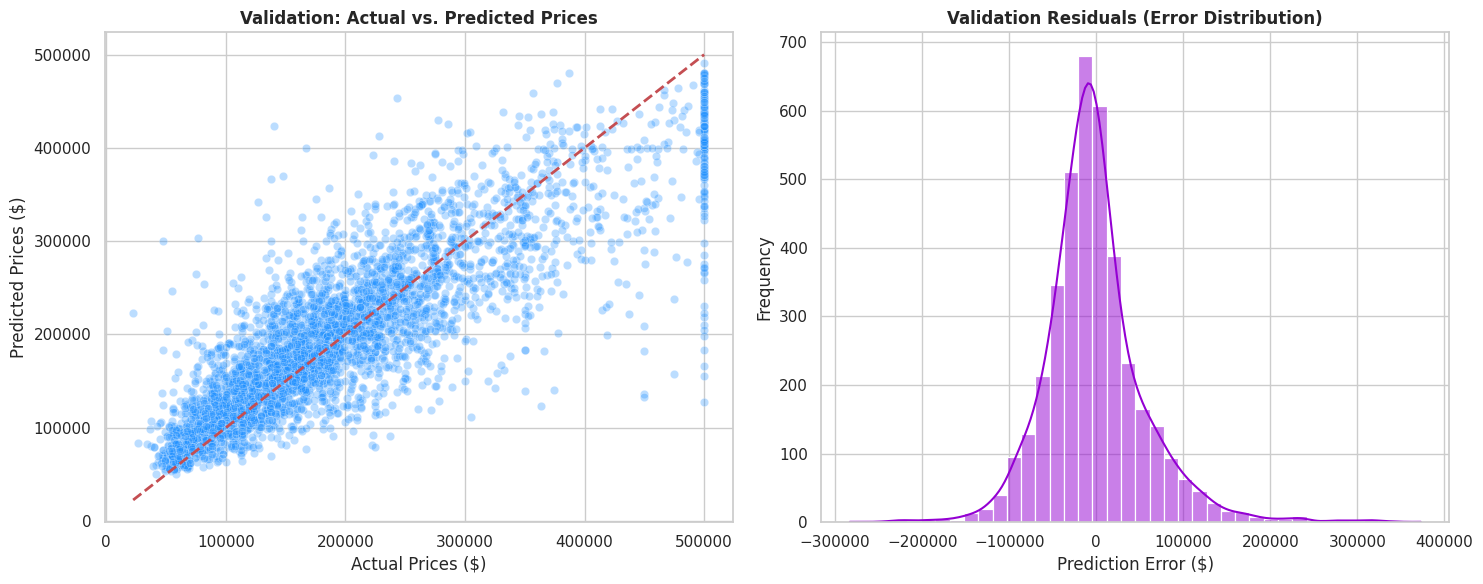

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Chart 1: Actual vs Predicted Prices Scatter Plot
sns.scatterplot(x=y_val, y=y_val_pred, alpha=0.3, ax=axes[0], color='dodgerblue')
axes[0].plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2)
axes[0].set_title('Validation: Actual vs. Predicted Prices', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Actual Prices ($)')
axes[0].set_ylabel('Predicted Prices ($)')

# Chart 2: Residuals Distribution Histogram
residuals = y_val - y_val_pred
sns.histplot(residuals, kde=True, ax=axes[1], color='darkviolet', bins=40)
axes[1].set_title('Validation Residuals (Error Distribution)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Prediction Error ($)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()